In [1]:
import pandas as pd 
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from matplotlib.patches import FancyBboxPatch

In [2]:

df = pd.read_csv("customer_growth_analytics.csv")
mkt = pd.read_csv("marketing_daily.csv").dropna(subset=["impressions"])
# 1) کسٹمر نے خریدا یا نہیں، یہ نشان پہلے لگا لیں (باقی خالی بھرنے سے پہلے)
df["has_order"] = df["order_id"].notna().map({True: "Yes", False: "No"})

# 2) متنی کالمز: خالی کی جگہ معنی خیز لفظ
df["signup_campaign"] = df["signup_campaign"].fillna("No Campaign")
df["referred_by"]     = df["referred_by"].fillna("Not Referred")
df["city"]            = df["city"].fillna("Unknown")
for col in ["order_id", "product_category", "order_status"]:
    df[col] = df[col].fillna("No Order")

# 3) نمبر والے کالمز: 0 اور پورے عدد (int)
df["acq_cost_pkr"] = df["acq_cost_pkr"].fillna(0)
for col in ["discount_pct", "order_amount", "gross_profit", "delivery_days", "rating"]:
    df[col] = df[col].fillna(0).astype(int)

# 4) تاریخیں: signup_date میں کوئی خالی نہیں، order_date میں خالی کو NaT رہنے دیں
df["signup_date"] = pd.to_datetime(df["signup_date"])
df["order_date"]  = pd.to_datetime(df["order_date"])

print(df.isnull().sum())   # order_date کے علاوہ سب 0 آئیں گے
print(df.dtypes)

customer_id               0
signup_date               0
acquisition_channel       0
signup_campaign           0
referred_by               0
gender                    0
city                      0
device                    0
acq_cost_pkr              0
order_id                  0
order_date             3723
product_category          0
discount_pct              0
order_amount              0
gross_profit              0
order_status              0
delivery_days             0
rating                    0
has_order                 0
dtype: int64
customer_id                    object
signup_date            datetime64[ns]
acquisition_channel            object
signup_campaign                object
referred_by                    object
gender                         object
city                           object
device                         object
acq_cost_pkr                  float64
order_id                       object
order_date             datetime64[ns]
product_category               object

In [3]:
df.head()

,customer_id,signup_date,acquisition_channel,signup_campaign,referred_by,gender,city,device,acq_cost_pkr,order_id,order_date,product_category,discount_pct,order_amount,gross_profit,order_status,delivery_days,rating,has_order
0,CUST-00002,2026-01-01,Instagram Ads,Winter Clearance,Not Referred,Male,Karachi,iOS,533.82,ORD-000001,2026-01-01,Footwear,15,2635,561,Delivered,3,5,Yes
1,CUST-00005,2026-01-01,Instagram Ads,Winter Clearance,Not Referred,Male,Faisalabad,Android,533.82,No Order,NaT,No Order,0,0,0,No Order,0,0,No
2,CUST-00006,2026-01-01,Instagram Ads,Winter Clearance,Not Referred,Female,Karachi,Android,533.82,ORD-000002,2026-01-01,Accessories,15,4080,1130,Delivered,5,0,Yes
3,CUST-00007,2026-01-01,Instagram Ads,Winter Clearance,Not Referred,Male,Peshawar,Desktop,533.82,No Order,NaT,No Order,0,0,0,No Order,0,0,No
4,CUST-00010,2026-01-01,Instagram Ads,Winter Clearance,Not Referred,Female,Karachi,Android,533.82,ORD-000003,2026-01-01,Footwear,20,4640,783,Delivered,3,0,Yes


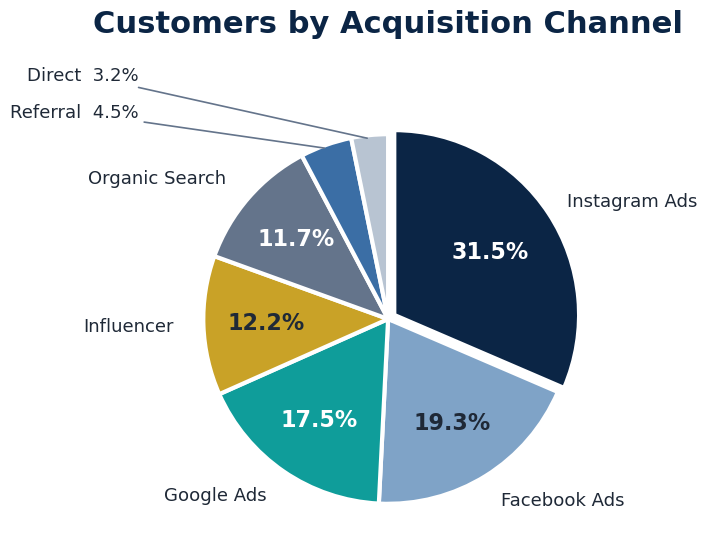

In [4]:


customers = df.drop_duplicates("customer_id")          # ہر کسٹمر ایک بار
counts = customers["acquisition_channel"].value_counts()

# Professional palette: Navy, Teal, Gold, Slate, Grey (बाक़ी चार्ट में भी यही रंग रहेंगे)
palette = {"Instagram Ads": "#0B2545", "Facebook Ads": "#7FA3C7", "Google Ads": "#0F9D9A",
           "Influencer": "#C9A227", "Organic Search": "#64748B", "Referral": "#3B6EA5", "Direct": "#B8C4D2"}
colors = [palette.get(c, "#B8C4D2") for c in counts.index]

def text_on(hex_color):                                    # गहरे रंग पर सफ़ेद, हल्के पर गहरा अक्षर
    r, g, b = [int(hex_color[i:i + 2], 16) for i in (1, 3, 5)]
    return "#FFFFFF" if (0.299 * r + 0.587 * g + 0.114 * b) < 150 else "#1F2937"

fig, ax = plt.subplots(figsize=(6, 6), facecolor="white")
wedges, _ = ax.pie(
    counts, colors=colors, startangle=90, counterclock=False,
    explode=[0.04] + [0] * (len(counts) - 1),              # सबसे بڑا हिस्सा हल्का बाहर
    wedgeprops=dict(edgecolor="white", linewidth=3),
)

total = counts.sum()
small = 0
for w, name, n, col in zip(wedges, counts.index, counts, colors):
    pct = n / total * 100
    ang = np.deg2rad((w.theta1 + w.theta2) / 2)
    x, y = np.cos(ang), np.sin(ang)
    if pct >= 6:                                           # बड़े हिस्से: % अंदर, नाम बाहर
        ax.text(0.66 * x, 0.66 * y, f"{pct:.1f}%", ha="center", va="center",
                fontsize=16, fontweight="bold", color=text_on(col))
        ax.text(1.16 * x, 1.16 * y, name, ha="left" if x > 0 else "right", va="center",
                fontsize=13, color="#1F2937")
    else:                                                  # छोटे हिस्से: तीर के साथ बाहर, ताकि आपस में न टकराएँ
        ax.annotate(f"{name}  {pct:.1f}%", xy=(x * 0.98, y * 0.98),
                    xytext=(-1.35 if x < 0 else 1.35, 1.12 + 0.2 * small),
                    ha="right" if x < 0 else "left", va="center", fontsize=13, color="#1F2937",
                    arrowprops=dict(arrowstyle="-", color="#64748B", lw=1.2))
        small += 1

ax.set_title("Customers by Acquisition Channel", fontsize=22, fontweight="bold",
             color="#0B2545", pad=40)
plt.savefig("AARRR 1.png", dpi=150, facecolor=fig.get_facecolor(), bbox_inches="tight")
plt.show()

gender               Female  Male
acquisition_channel              
Facebook Ads           1139   967
Google Ads              972   938
Instagram Ads          2135  1292
gender               Female  Male
acquisition_channel              
Facebook Ads           54.1  45.9
Google Ads             50.9  49.1
Instagram Ads          62.3  37.7


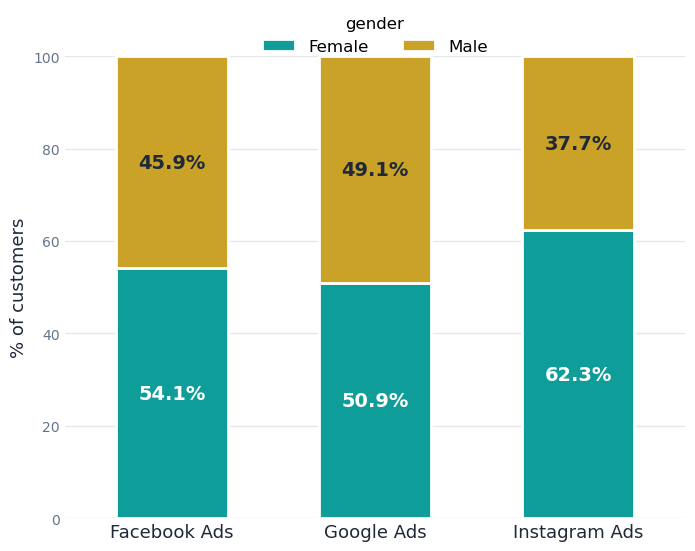

In [5]:
channels = ["Instagram Ads", "Facebook Ads", "Google Ads"]

customers = df.drop_duplicates("customer_id")                       # ہر کسٹمر ایک بار
ads = customers[customers["acquisition_channel"].isin(channels)]    # صرف تین اشتہاری چینلز

# تعداد
print(pd.crosstab(ads["acquisition_channel"], ads["gender"]))

# فیصد: ہر چینل کی قطار 100% بنتی ہے
pct = pd.crosstab(ads["acquisition_channel"], ads["gender"], normalize="index") * 100
print(pct.round(1))

# چارٹ (Professional palette: Teal + Gold)
gender_colors = {"Female": "#0F9D9A", "Male": "#C9A227"}
text_colors = {"Female": "white", "Male": "#1F2937"}

fig, ax = plt.subplots(figsize=(8, 6), facecolor="white")
pct.plot(kind="bar", stacked=True, ax=ax, width=0.55,
         color=[gender_colors.get(c, "#B8C4D2") for c in pct.columns],
         edgecolor="white", linewidth=2)

# हर हिस्से के बीच में उसका %
for container, col in zip(ax.containers, pct.columns):
    ax.bar_label(container, labels=[f"{v:.1f}%" for v in pct[col]], label_type="center",
                 fontsize=14, fontweight="bold", color=text_colors.get(col, "#1F2937"))

ax.set_facecolor("white")
ax.set_ylim(0, 100)
ax.set_ylabel("% of customers", fontsize=13, color="#1F2937")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=0, labelsize=13, colors="#1F2937", length=0)
ax.tick_params(axis="y", colors="#64748B", length=0)
ax.grid(axis="y", color="#E5E7EB", linewidth=1)
ax.set_axisbelow(True)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(title="gender", frameon=False, fontsize=12, title_fontsize=12,
          loc="upper center", bbox_to_anchor=(0.5, 1.12), ncol=2)

plt.savefig("AARRR 2.png", dpi=150, facecolor=fig.get_facecolor(), bbox_inches="tight")
plt.show()

gender      Female  Male  Total
city                           
Karachi        970   705   1675
Lahore         844   630   1474
Peshawar       500   371    871
Islamabad      425   295    720
Rawalpindi     337   263    600
Faisalabad     313   219    532
Multan         189   176    365
Mardan         144   125    269
Hyderabad      132   106    238
Quetta         125   102    227
Abbottabad     127    97    224
Sialkot        120    96    216


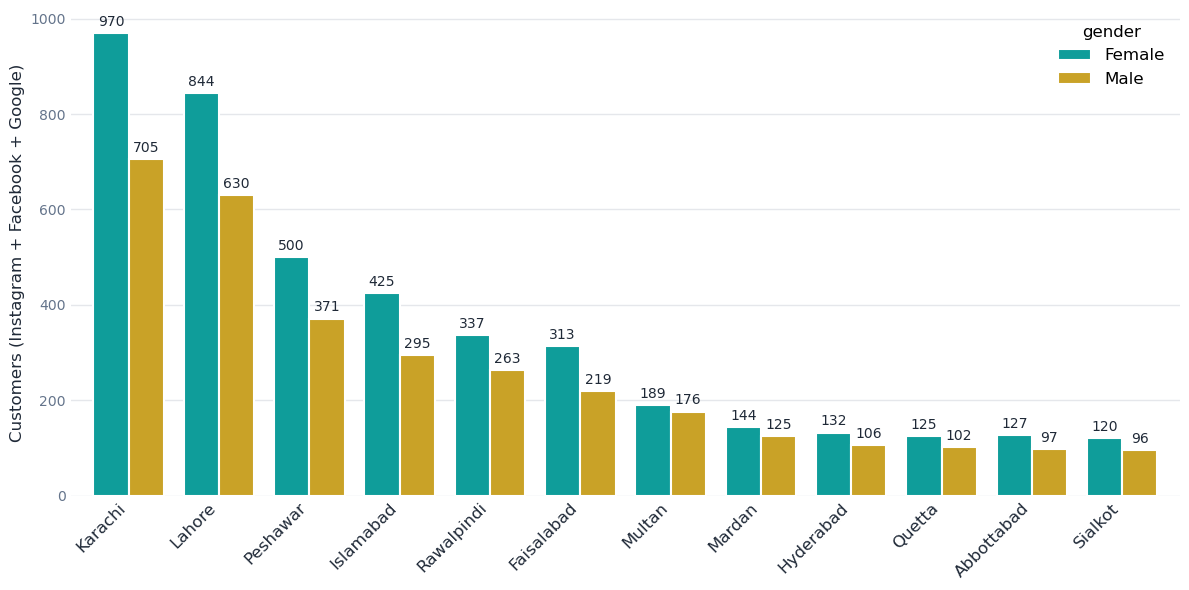

In [6]:
channels = ["Instagram Ads", "Facebook Ads", "Google Ads"]

customers = df.drop_duplicates("customer_id")                        # ہر کسٹمر ایک بار
ads = customers[customers["acquisition_channel"].isin(channels)]     # تینوں چینلز ملا کر
ads = ads[ads["city"] != "Unknown"]                                  # خالی شہر نکال دیں

tbl = pd.crosstab(ads["city"], ads["gender"])
tbl["Total"] = tbl.sum(axis=1)
tbl = tbl.sort_values("Total", ascending=False)
print(tbl)

# چارٹ: ہر شہر کے Male اور Female (Professional palette: Teal + Gold)
gender_colors = {"Female": "#0F9D9A", "Male": "#C9A227"}
plot_df = tbl.drop(columns="Total")

fig, ax = plt.subplots(figsize=(12, 6), facecolor="white")
plot_df.plot(kind="bar", ax=ax, width=0.78, edgecolor="white", linewidth=1.5,
             color=[gender_colors.get(c, "#B8C4D2") for c in plot_df.columns])

# हर bar के ऊपर उसकी संख्या
for container in ax.containers:
    ax.bar_label(container, fontsize=10, color="#1F2937", padding=3)

ax.set_facecolor("white")
ax.set_ylabel("Customers (Instagram + Facebook + Google)", fontsize=12, color="#1F2937")
ax.set_xlabel("")
ax.tick_params(axis="x", rotation=45, labelsize=12, colors="#1F2937", length=0)
plt.setp(ax.get_xticklabels(), ha="right")
ax.tick_params(axis="y", colors="#64748B", length=0)
ax.grid(axis="y", color="#E5E7EB", linewidth=1)
ax.set_axisbelow(True)
for s in ax.spines.values():
    s.set_visible(False)
ax.legend(title="gender", frameon=False, fontsize=12, title_fontsize=12, loc="upper right")

plt.tight_layout()
plt.savefig("AARRR 3.png", dpi=150, facecolor=fig.get_facecolor())
plt.show()

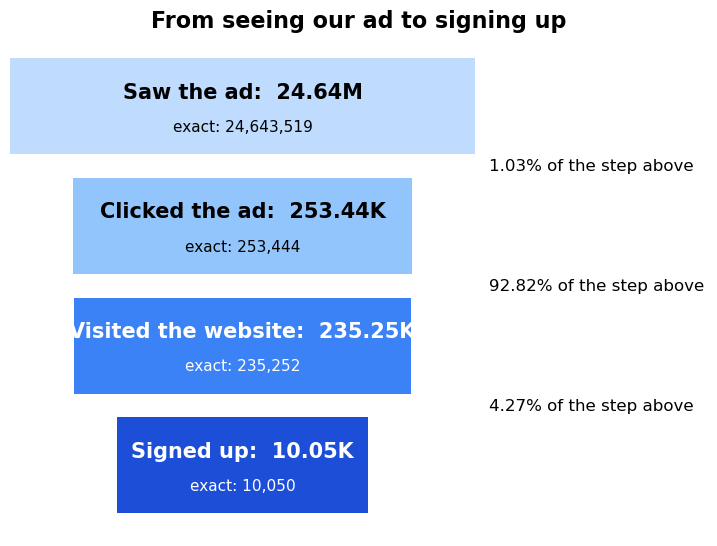

In [7]:
vals = [int(mkt[c].sum()) for c in ["impressions", "clicks", "sessions", "signups"]]
names = ["Saw the ad", "Clicked the ad", "Visited the website", "Signed up"]
short = lambda v: f"{v/1e6:.2f}M" if v >= 1e6 else f"{v/1e3:.2f}K"

w = np.log10(vals) / np.log10(vals[0])
fig, ax = plt.subplots(figsize=(9, 6.5))
for i, (n, v) in enumerate(zip(names, vals)):
    ax.barh(-i, w[i], left=(1 - w[i]) / 2, color=["#BFDBFE", "#93C5FD", "#3B82F6", "#1D4ED8"][i])
    c = "white" if i > 1 else "black"
    ax.text(0.5, -i + 0.12, f"{n}:  {short(v)}", ha="center", va="center", fontsize=15, fontweight="bold", color=c)
    ax.text(0.5, -i - 0.17, f"exact: {v:,}", ha="center", va="center", fontsize=11, color=c)
    if i: ax.text(1.03, -i + 0.5, f"{v/vals[i-1]:.2%} of the step above", va="center", fontsize=12)
ax.set_title("From seeing our ad to signing up", fontsize=16, fontweight="bold")
plt.savefig("AARRR 4.png", dpi=120)
ax.set_xlim(0, 1.5); ax.axis("off"); plt.show()

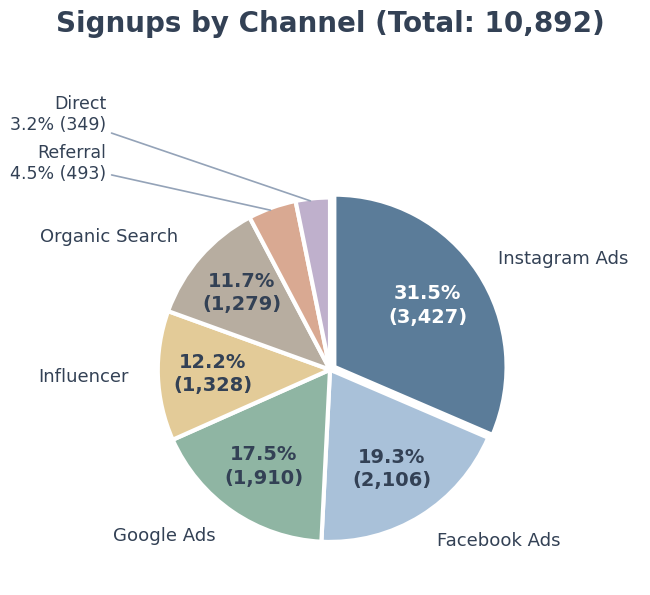

In [8]:
import numpy as np
import matplotlib.pyplot as plt

signups = df.drop_duplicates("customer_id")["acquisition_channel"].value_counts()

# Soft professional palette
palette = {"Instagram Ads": "#5B7C99",   # धूसर नीला
           "Facebook Ads": "#A9C1D9",    # हल्का आसमानी
           "Google Ads":   "#8FB5A3",    # पुदीना-हरा
           "Influencer":   "#E3CB98",    # रेत जैसा पीला
           "Organic Search": "#B7ADA0",  # गर्म ग्रे
           "Referral":     "#D9A992",    # मिट्टी जैसा गुलाबी
           "Direct":       "#BFB0CC"}    # हल्का बैंगनी
colors = [palette.get(c, "#CBD5E1") for c in signups.index]

def text_on(hex_color):                                    # गहरे रंग पर सफ़ेद, हल्के पर गहरा अक्षर
    r, g, b = [int(hex_color[i:i + 2], 16) for i in (1, 3, 5)]
    return "#FFFFFF" if (0.299 * r + 0.587 * g + 0.114 * b) < 130 else "#334155"

fig, ax = plt.subplots(figsize=(8, 8), facecolor="white")
wedges, _ = ax.pie(signups, colors=colors, startangle=90, counterclock=False,
                   explode=[0.03] + [0] * (len(signups) - 1),
                   wedgeprops=dict(edgecolor="white", linewidth=3))

total, small = signups.sum(), 0
for w, name, n, col in zip(wedges, signups.index, signups, colors):
    pct = n / total * 100
    ang = np.deg2rad((w.theta1 + w.theta2) / 2)
    x, y = np.cos(ang), np.sin(ang)
    if pct >= 6:                                           # बड़े हिस्से: % और संख्या अंदर, नाम बाहर
        ax.text(0.68 * x, 0.68 * y, f"{pct:.1f}%\n({n:,})", ha="center", va="center",
                fontsize=14, fontweight="bold", color=text_on(col), linespacing=1.3)
        ax.text(1.17 * x, 1.17 * y, name, ha="left" if x > 0 else "right", va="center",
                fontsize=13, color="#334155")
    else:                                                  # छोटे हिस्से: तीर के साथ बाहर
        ax.annotate(f"{name}\n{pct:.1f}% ({n:,})", xy=(x * 0.98, y * 0.98),
                    xytext=(-1.3 if x < 0 else 1.3, 1.2 + 0.28 * small),
                    ha="right" if x < 0 else "left", va="center", fontsize=12.5, color="#334155",
                    arrowprops=dict(arrowstyle="-", color="#94A3B8", lw=1.2))
        small += 1

ax.set_xlim(-1.8, 1.8)
ax.set_ylim(-1.25, 1.8)
ax.set_title(f"Signups by Channel (Total: {total:,})", fontsize=20, fontweight="bold",
             color="#334155", pad=20)
plt.savefig("AARRR 5.png", dpi=150, facecolor=fig.get_facecolor(), bbox_inches="tight")
plt.show()

Total customers: 10892
Overall churn rate: 85.1%
Retention rate:     14.9%
segment
One-time      9269
Occasional    1571
Regular         52
Name: count, dtype: int64


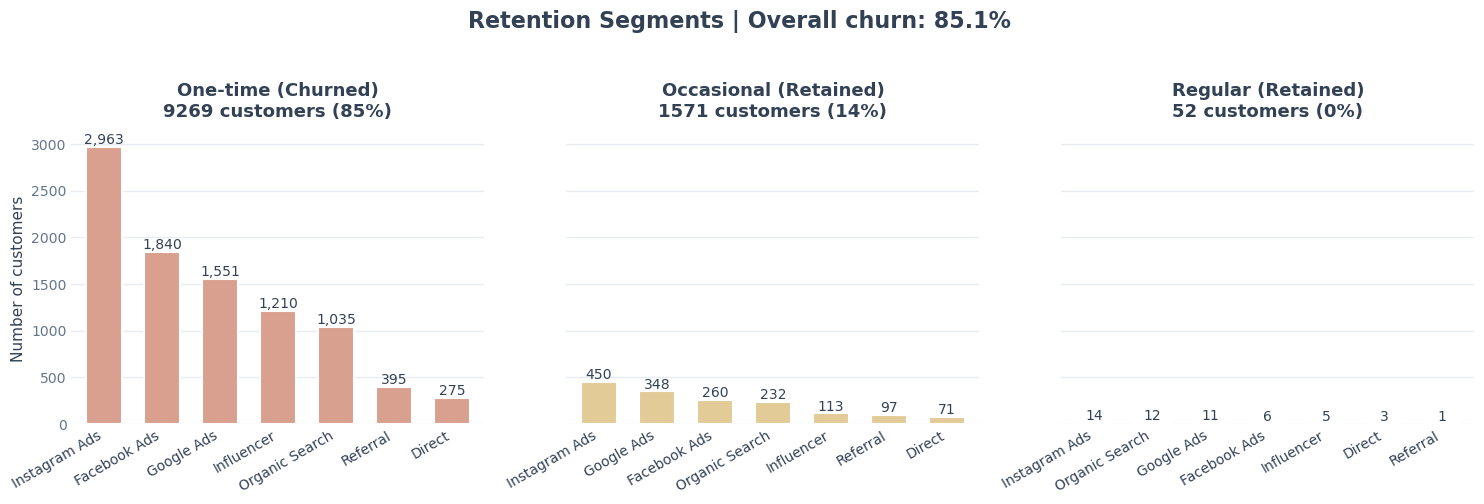

In [9]:
import numpy as np
import matplotlib.pyplot as plt

# 1) हर customer के कितने orders (column नाम अपने डेटा के हिसाب से बदलें)
orders = df.groupby("customer_id")["order_id"].nunique().rename("orders")

# 2) हर customer एक बार
cust = df.drop_duplicates("customer_id").set_index("customer_id").join(orders)

# 3) Segment (सिर्फ़ orders की गिनती से)
labels = ["One-time", "Occasional", "Regular"]
cust["segment"] = pd.cut(cust["orders"], bins=[0, 1, 3, float("inf")], labels=labels)

# 4) Churn: जो एक बार आया और दोबारा नहीं आया
cust["churned"] = cust["segment"] == "One-time"

# 5) संख्याएँ
total = len(cust)
churn_rate = cust["churned"].mean() * 100
print(f"Total customers: {total}")
print(f"Overall churn rate: {churn_rate:.1f}%")
print(f"Retention rate:     {100 - churn_rate:.1f}%")
print(cust["segment"].value_counts())

# 6) तीन चार्ट, हर segment के customers किस channel से आए (Soft palette)
colors = ["#D9A08F", "#E3CB98", "#8FB5A3"]          # मिट्टी जैसा गुलाबी, रेत जैसा पीला, पुदीना-हरा
status = {"One-time": "Churned", "Occasional": "Retained", "Regular": "Retained"}
INK, MUTED, GRID = "#334155", "#64748B", "#E8ECF1"

fig, axes = plt.subplots(1, 3, figsize=(15, 4.8), sharey=True, facecolor="white")

for ax, seg, color in zip(axes, labels, colors):
    sub = cust[cust["segment"] == seg]
    share = len(sub) / total * 100
    vc = sub["acquisition_channel"].value_counts()
    vc.plot(kind="bar", ax=ax, color=color, width=0.62, edgecolor="white", linewidth=1.5)

    for i, v in enumerate(vc.values):                # हर bar के ऊपर संख्या
        ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=10, color=INK)

    ax.set_title(f"{seg} ({status[seg]})\n{len(sub)} customers ({share:.0f}%)",
                 fontsize=13, fontweight="bold", color=INK, pad=12)
    ax.set_xlabel("")
    ax.tick_params(axis="x", rotation=30, labelsize=10, colors=INK, length=0)
    plt.setp(ax.get_xticklabels(), ha="right")
    ax.tick_params(axis="y", colors=MUTED, length=0)
    ax.grid(axis="y", color=GRID, linewidth=1)
    ax.set_axisbelow(True)
    ax.set_facecolor("white")
    for s in ax.spines.values():
        s.set_visible(False)

axes[0].set_ylabel("Number of customers", fontsize=11, color=INK)
fig.suptitle(f"Retention Segments | Overall churn: {churn_rate:.1f}%", y=1.04,
             fontsize=16, fontweight="bold", color=INK)
plt.tight_layout()
plt.savefig("AARRR 6.png", dpi=150, facecolor=fig.get_facecolor(), bbox_inches="tight")
plt.show()

Active per month: [1690, 2729, 4200]
New: [1690, 2343, 3136] Returning: [0, 386, 1064]
Funnel: [1690, 386, 138]


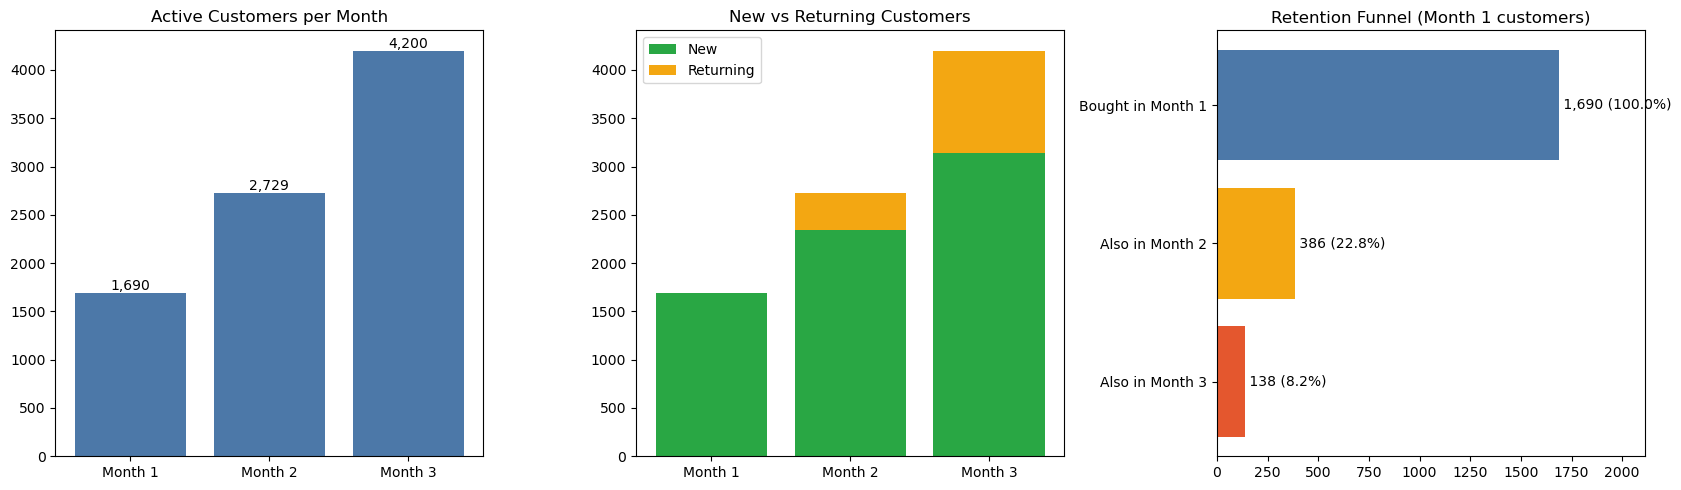

In [10]:


# column नाम अपने डेटा के हिसाब से बदलें
df["order_date"] = pd.to_datetime(df["order_date"])

# 1) हर order को महीना 1, 2 या 3 दें (30-30 दिन के हिस्से)
start = df["order_date"].min()
df["month"] = ((df["order_date"] - start).dt.days // 30 + 1).clip(upper=3)

# 2) हर महीने के customers का set
m = {i: set(df.loc[df["month"] == i, "customer_id"]) for i in (1, 2, 3)}

# 3) नए बनाम पुराने customers
new_c, ret_c = [], []
seen = set()
for i in (1, 2, 3):
    new_c.append(len(m[i] - seen))
    ret_c.append(len(m[i] & seen))
    seen |= m[i]

# 4) Funnel: M1 -> M2 -> M3
f1 = len(m[1])
f2 = len(m[1] & m[2])
f3 = len(m[1] & m[2] & m[3])
funnel = [f1, f2, f3]
print("Active per month:", [len(m[i]) for i in (1, 2, 3)])
print("New:", new_c, "Returning:", ret_c)
print("Funnel:", funnel)

# 5) चार्ट
fig, axes = plt.subplots(1, 3, figsize=(17, 5))

# (a) हर महीने के active customers
actives = [len(m[i]) for i in (1, 2, 3)]
axes[0].bar(["Month 1", "Month 2", "Month 3"], actives, color="#4C78A8")
axes[0].set_title("Active Customers per Month")
for x, v in enumerate(actives):
    axes[0].text(x, v, f"{v:,}", ha="center", va="bottom")

# (b) नए बनाम पुराने
axes[1].bar(["Month 1", "Month 2", "Month 3"], new_c, label="New", color="#29A744")
axes[1].bar(["Month 1", "Month 2", "Month 3"], ret_c, bottom=new_c, label="Returning", color="#F3A712")
axes[1].set_title("New vs Returning Customers")
axes[1].legend()

# (c) Retention funnel
names = ["Bought in Month 1", "Also in Month 2", "Also in Month 3"]
axes[2].barh(names[::-1], funnel[::-1], color=["#E4572E", "#F3A712", "#4C78A8"])
axes[2].set_title("Retention Funnel (Month 1 customers)")
for y, v in enumerate(funnel[::-1]):
    pct = v / f1 * 100
    axes[2].text(v, y, f" {v:,} ({pct:.1f}%)", va="center")
axes[2].set_xlim(0, f1 * 1.25)

plt.tight_layout()
plt.savefig("AARRR 7.png", dpi=120)
plt.show()

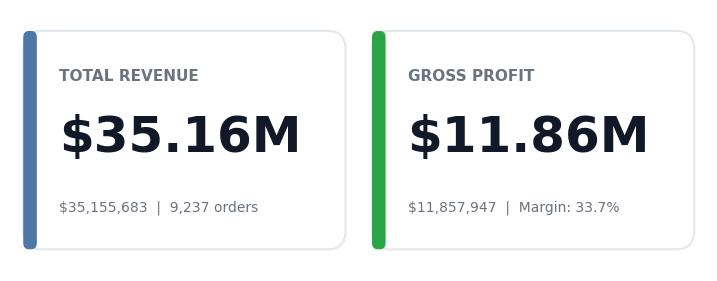

In [11]:


# ---- अपने डेटा के हिसाब से बदलें ----
amount_col = "order_amount"          # sales की रकम वाला column
profit_col = "gross_profit"    # profit वाला column
currency = "$"                 # अपनी करेंसी लिखें (Rs, PKR, $ ...)
# --------------------------------------

revenue = df[amount_col].sum()
profit = df[profit_col].sum()
margin = profit / revenue * 100
orders = df["order_id"].nunique()

def compact(n):
    for limit, suffix in [(1e9, "B"), (1e6, "M"), (1e3, "K")]:
        if abs(n) >= limit:
            return f"{n / limit:.2f}{suffix}"
    return f"{n:,.0f}"

fig, ax = plt.subplots(figsize=(9, 3.4))
ax.set_xlim(0, 20)
ax.set_ylim(0, 7)
ax.axis("off")

def draw_card(x, color, label, value, sub):
    ax.add_patch(FancyBboxPatch((x, 0.6), 9.2, 5.8,
                 boxstyle="round,pad=0.02,rounding_size=0.5",
                 facecolor="#FFFFFF", edgecolor="#E3E8EF", linewidth=1.5))
    ax.add_patch(FancyBboxPatch((x, 0.6), 0.35, 5.8,
                 boxstyle="round,pad=0.02,rounding_size=0.17",
                 facecolor=color, edgecolor="none"))
    ax.text(x + 1.0, 5.1, label, fontsize=11, color="#6B7280", fontweight="bold")
    ax.text(x + 1.0, 3.2, value, fontsize=36, color="#111827", fontweight="bold")
    ax.text(x + 1.0, 1.6, sub, fontsize=10, color="#6B7280")

draw_card(0.4, "#4C78A8", "TOTAL REVENUE",
          f"{currency}{compact(revenue)}",
          f"{currency}{revenue:,.0f}  |  {orders:,} orders")

draw_card(10.4, "#29A744", "GROSS PROFIT",
          f"{currency}{compact(profit)}",
          f"{currency}{profit:,.0f}  |  Margin: {margin:.1f}%")
plt.savefig("AARRR 8.png", dpi=120)

plt.show()

In [12]:
mkt

,date,channel,campaign_name,spend_pkr,impressions,clicks,sessions,signups
0,2026-01-01,Instagram Ads,Winter Clearance,10650,48462.0,501.0,461,17
1,2026-01-01,Facebook Ads,Winter Clearance,9830,57867.0,540.0,497,21
2,2026-01-01,Google Ads,Winter Clearance,9490,7409.0,254.0,234,17
3,2026-01-01,Influencer,Winter Clearance,15530,176715.0,1038.0,955,40
4,2026-01-01,Organic Search,NaN,0,6393.0,207.0,207,13
...,...,...,...,...,...,...,...,...
623,2026-03-31,Instagram Ads,Post-Eid Clearance,39850,121700.0,1433.0,1318,42
624,2026-03-31,Facebook Ads,Post-Eid Clearance,29350,128912.0,1211.0,1114,37
625,2026-03-31,Google Ads,Post-Eid Clearance,15070,11735.0,366.0,337,24
626,2026-03-31,Influencer,Post-Eid Clearance,0,149875.0,1009.0,928,20


In [13]:
df

,customer_id,signup_date,acquisition_channel,signup_campaign,referred_by,gender,city,device,acq_cost_pkr,order_id,order_date,product_category,discount_pct,order_amount,gross_profit,order_status,delivery_days,rating,has_order,month
0,CUST-00002,2026-01-01,Instagram Ads,Winter Clearance,Not Referred,Male,Karachi,iOS,533.82,ORD-000001,2026-01-01,Footwear,15,2635,561,Delivered,3,5,Yes,1.0
1,CUST-00005,2026-01-01,Instagram Ads,Winter Clearance,Not Referred,Male,Faisalabad,Android,533.82,No Order,NaT,No Order,0,0,0,No Order,0,0,No,NaN
2,CUST-00006,2026-01-01,Instagram Ads,Winter Clearance,Not Referred,Female,Karachi,Android,533.82,ORD-000002,2026-01-01,Accessories,15,4080,1130,Delivered,5,0,Yes,1.0
3,CUST-00007,2026-01-01,Instagram Ads,Winter Clearance,Not Referred,Male,Peshawar,Desktop,533.82,No Order,NaT,No Order,0,0,0,No Order,0,0,No,NaN
4,CUST-00010,2026-01-01,Instagram Ads,Winter Clearance,Not Referred,Female,Karachi,Android,533.82,ORD-000003,2026-01-01,Footwear,20,4640,783,Delivered,3,0,Yes,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12954,CUST-10888,2026-03-31,Referral,Referral Program,CUST-08724,Male,Quetta,Android,300.00,ORD-009236,2026-03-31,Men's Wear,0,1950,721,Delivered,5,5,Yes,3.0
12955,CUST-10889,2026-03-31,Direct,No Campaign,Not Referred,Male,Quetta,Android,0.00,No Order,NaT,No Order,0,0,0,No Order,0,0,No,NaN
12956,CUST-10890,2026-03-31,Direct,No Campaign,Not Referred,Female,Mardan,Android,0.00,No Order,NaT,No Order,0,0,0,No Order,0,0,No,NaN
12957,CUST-10891,2026-03-31,Direct,No Campaign,Not Referred,Male,Peshawar,Android,0.00,No Order,NaT,No Order,0,0,0,No Order,0,0,No,NaN


In [14]:
Acquisition_cost=df['acq_cost_pkr'].sum()

In [15]:
customer=df['customer_id'].nunique()

In [16]:
cac=Acquisition_cost / customer

In [17]:
cac

np.float64(541.3243325376422)

In [18]:
Acquisition_cost = df['acq_cost_pkr'].sum()
customer = df['customer_id'].nunique()
cac = Acquisition_cost / customer
print(f"CAC: PKR {cac:,.2f}")

CAC: PKR 541.32


In [19]:
print("Total cost:", Acquisition_cost)
print("Unique customers:", customer)
print("CAC:", Acquisition_cost / customer)
print("Rows:", len(df))
print("Duplicate customer rows:", df.duplicated('customer_id').sum())

Total cost: 5896104.63
Unique customers: 10892
CAC: 541.3243325376422
Rows: 12959
Duplicate customer rows: 2067


In [20]:
lifetime_value=df['gross_profit'].sum()

In [21]:
ltv=lifetime_value /customer

In [22]:
print(f"LTV: PKR {ltv:,.2f}")

LTV: PKR 1,088.68


In [23]:
ltv_cac_ratio = ltv / cac
print(f"LTV:CAC ratio: {ltv_cac_ratio:.2f}")

LTV:CAC ratio: 2.01


In [24]:
g = df.groupby('acquisition_channel').agg(
    cost=('acq_cost_pkr', 'sum'),
    customers=('customer_id', 'nunique'),
    gross_profit=('gross_profit', 'sum')
)
g['cac'] = g['cost'] / g['customers']
g['ltv'] = g['gross_profit'] / g['customers']
g['ltv_cac'] = g['ltv'] / g['cac']
print(g.sort_values('ltv_cac'))

                           cost  customers  gross_profit         cac  \
acquisition_channel                                                    
Influencer            918289.24       1328       1154427  691.482861   
Facebook Ads         1493355.76       2106       1959059  709.095802   
Instagram Ads        2238485.84       3427       3630165  653.191083   
Google Ads           1098073.79       1910       2426171  574.907743   
Referral              147900.00        493        646301  300.000000   
Direct                     0.00        349        484808    0.000000   
Organic Search             0.00       1279       1557016    0.000000   

                             ltv   ltv_cac  
acquisition_channel                         
Influencer            869.297440  1.257150  
Facebook Ads          930.227445  1.311850  
Instagram Ads        1059.283630  1.621706  
Google Ads           1270.246597  2.209479  
Referral             1310.955375  4.369851  
Direct               1389.134670    

In [25]:
df

,customer_id,signup_date,acquisition_channel,signup_campaign,referred_by,gender,city,device,acq_cost_pkr,order_id,order_date,product_category,discount_pct,order_amount,gross_profit,order_status,delivery_days,rating,has_order,month
0,CUST-00002,2026-01-01,Instagram Ads,Winter Clearance,Not Referred,Male,Karachi,iOS,533.82,ORD-000001,2026-01-01,Footwear,15,2635,561,Delivered,3,5,Yes,1.0
1,CUST-00005,2026-01-01,Instagram Ads,Winter Clearance,Not Referred,Male,Faisalabad,Android,533.82,No Order,NaT,No Order,0,0,0,No Order,0,0,No,NaN
2,CUST-00006,2026-01-01,Instagram Ads,Winter Clearance,Not Referred,Female,Karachi,Android,533.82,ORD-000002,2026-01-01,Accessories,15,4080,1130,Delivered,5,0,Yes,1.0
3,CUST-00007,2026-01-01,Instagram Ads,Winter Clearance,Not Referred,Male,Peshawar,Desktop,533.82,No Order,NaT,No Order,0,0,0,No Order,0,0,No,NaN
4,CUST-00010,2026-01-01,Instagram Ads,Winter Clearance,Not Referred,Female,Karachi,Android,533.82,ORD-000003,2026-01-01,Footwear,20,4640,783,Delivered,3,0,Yes,1.0
...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...,...
12954,CUST-10888,2026-03-31,Referral,Referral Program,CUST-08724,Male,Quetta,Android,300.00,ORD-009236,2026-03-31,Men's Wear,0,1950,721,Delivered,5,5,Yes,3.0
12955,CUST-10889,2026-03-31,Direct,No Campaign,Not Referred,Male,Quetta,Android,0.00,No Order,NaT,No Order,0,0,0,No Order,0,0,No,NaN
12956,CUST-10890,2026-03-31,Direct,No Campaign,Not Referred,Female,Mardan,Android,0.00,No Order,NaT,No Order,0,0,0,No Order,0,0,No,NaN
12957,CUST-10891,2026-03-31,Direct,No Campaign,Not Referred,Male,Peshawar,Android,0.00,No Order,NaT,No Order,0,0,0,No Order,0,0,No,NaN


Customers without a valid date (excluded): 3723 of 10892
count    7169.0
mean       31.6
std        23.7
min         1.0
25%        13.0
50%        24.0
75%        47.0
max        90.0
Name: recency, dtype: float64
R
1    1434
2    1434
3    1433
4    1434
5    1434
Name: count, dtype: int64


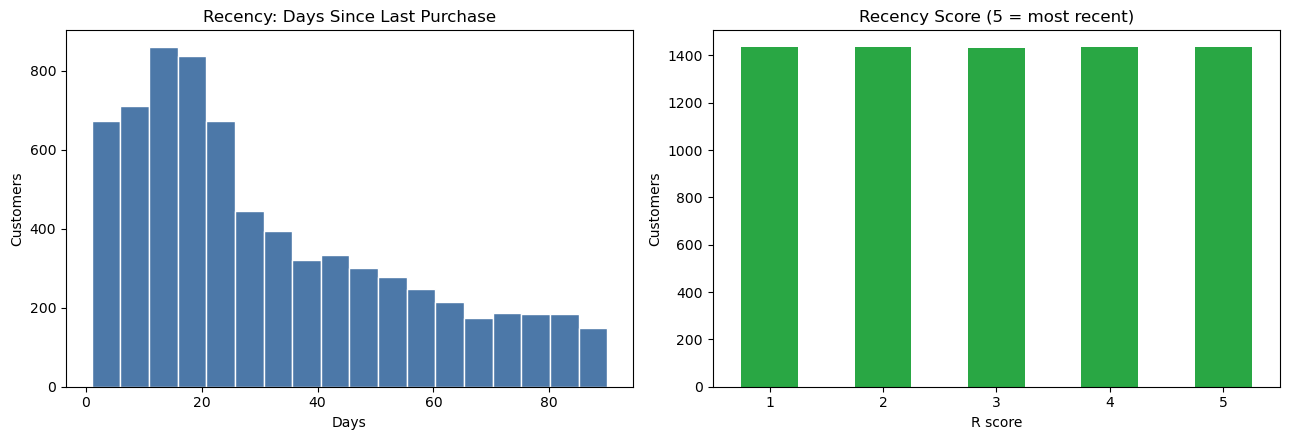

In [38]:


# column naam apne data ke hisaab se badlein
df["order_date"] = pd.to_datetime(df["order_date"], errors="coerce")

# 1) Reference date
snapshot = df["order_date"].max() + pd.Timedelta(days=1)

# 2) Har customer ka last order aur Recency (din)
rfm = df.groupby("customer_id").agg(last_order=("order_date", "max"))
rfm["recency"] = (snapshot - rfm["last_order"]).dt.days

# 3) Bina valid date wale customers alag karein
missing = rfm["recency"].isna().sum()
print(f"Customers without a valid date (excluded): {missing} of {len(rfm)}")
rfm = rfm.dropna(subset=["recency"]).copy()

print(rfm["recency"].describe().round(1))

# 4) Recency score: 5 = sabse recent, 1 = sabse purana
rfm["R"] = pd.qcut(rfm["recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
print(rfm["R"].value_counts().sort_index())

# 5) Chart
fig, axes = plt.subplots(1, 2, figsize=(13, 4.5))

axes[0].hist(rfm["recency"], bins=18, color="#4C78A8", edgecolor="white")
axes[0].set_title("Recency: Days Since Last Purchase")
axes[0].set_xlabel("Days")
axes[0].set_ylabel("Customers")

rfm["R"].value_counts().sort_index().plot(kind="bar", ax=axes[1], color="#29A744")
axes[1].set_title("Recency Score (5 = most recent)")
axes[1].set_xlabel("R score")
axes[1].set_ylabel("Customers")
axes[1].tick_params(axis="x", rotation=0)

plt.tight_layout()
plt.savefig("AARRR 9.png", dpi=120)
plt.show()

In [34]:
# 1) Har customer ke orders
freq = df.groupby("customer_id")["order_id"].nunique()
rfm["frequency"] = freq.reindex(rfm.index).fillna(0).astype(int)

# 2) Frequency score: 1 order = 1, 2 = 2, 3 = 3, 4 = 4, 5 ya zyada = 5
rfm["F"] = pd.cut(rfm["frequency"], bins=[0, 1, 2, 3, 4, float("inf")],
                  labels=[1, 2, 3, 4, 5]).astype(int)

print(rfm[["frequency", "F"]].head())
print(rfm["F"].value_counts().sort_index())

             frequency  F
customer_id              
CUST-00001           2  2
CUST-00002           2  2
CUST-00003           1  1
CUST-00004           1  1
CUST-00006           1  1
F
1    5546
2    1235
3     336
4      48
5       4
Name: count, dtype: int64


In [37]:

# ---------- Column names (apne data ke hisaab se badlein) ----------
CUST, ORDER, DATE, PROFIT = "customer_id", "order_id", "order_date", "gross_profit"

# ---------- Date saaf karo ----------
df[DATE] = pd.to_datetime(df[DATE], errors="coerce")
d = df.dropna(subset=[DATE])                       # missing date wali rows hata do
snapshot = d[DATE].max() + pd.Timedelta(days=1)    # aakhri date ke ek din baad

# ---------- R, F, M ek saath ----------
rfm = d.groupby(CUST).agg(
    recency=(DATE, lambda x: (snapshot - x.max()).days),   # aakhri order ko kitne din hue
    frequency=(ORDER, "nunique"),                          # kitne orders
    monetary=(PROFIT, "sum"),                              # kul gross profit
)

# ---------- Scores (5 = best, 1 = worst) ----------
rfm["R"] = pd.qcut(rfm["recency"].rank(method="first"), 5, labels=[5, 4, 3, 2, 1]).astype(int)
rfm["F"] = pd.cut(rfm["frequency"], bins=[0, 1, 2, 3, 4, float("inf")], labels=[1, 2, 3, 4, 5]).astype(int)
rfm["M"] = pd.qcut(rfm["monetary"].rank(method="first"), 5, labels=[1, 2, 3, 4, 5]).astype(int)
rfm["RFM_Score"] = rfm["R"].astype(str) + rfm["F"].astype(str) + rfm["M"].astype(str)

# ---------- Segments ----------
def segment(r):
    if r["R"] >= 4 and r["F"] >= 4 and r["M"] >= 4:
        return "Champions"
    if r["F"] >= 3 and r["R"] >= 3:
        return "Loyal"
    if r["R"] <= 2 and r["F"] >= 3:
        return "At Risk"
    if r["R"] <= 2 and r["F"] <= 2:
        return "Lost"
    return "Others"

rfm["Segment"] = rfm.apply(segment, axis=1)

# ---------- Output ----------
print(rfm.head())
print(rfm["Segment"].value_counts())
print(rfm.groupby("Segment")[["recency", "frequency", "monetary"]].mean().round(2))

             recency  frequency  monetary  R  F  M RFM_Score Segment
customer_id                                                         
CUST-00001        57          2      3428  1  2  5       125    Lost
CUST-00002        59          2      2364  1  2  4       124    Lost
CUST-00003        89          1      1371  1  1  3       113    Lost
CUST-00004        89          1      1959  1  1  4       114    Lost
CUST-00006        90          1      1130  1  1  3       113    Lost
Segment
Others       3956
Lost         2825
Loyal         301
Champions      44
At Risk        43
Name: count, dtype: int64
           recency  frequency  monetary
Segment                                
At Risk      41.65       3.00   4412.65
Champions    11.57       4.09   5166.86
Lost         56.53       1.11   1578.61
Loyal        14.75       3.03   3860.42
Others       15.22       1.23   1471.00
